# Score de crédit pour une clientèle de particuliers

**Objectif** : estimer la probabilité de défaut (PD) à 12 mois d'un client, puis la traduire en **grille de score** et en **échelle de notation**.

**Défaut** : plus de 90 jours de retard de paiement sur les 12 mois qui suivent la date d'observation.

**Démarche**
1. Exploration de la base : 5 752 observations de 2 289 clients, sur 4 dates d'observation (2018 à 2021).
2. Validation **hors période** : apprentissage sur 2018-2020, test sur 2021. C'est la pratique des banques pour valider un modèle de notation.
3. Encodage **WoE** appris sur l'apprentissage seulement. Le nombre de classes par variable est réglé par validation croisée.
4. Sélection : Information Value, puis filtre de corrélation, puis stepwise.
5. **Régression logistique** réglée. Il n'y a pas de rééquilibrage, pour que les PD restent calibrées sur le vrai taux de défaut.
6. Comparaison avec un **modèle challenger** (gradient boosting réglé).
7. **Grille de score** en points et **échelle de notation**, construites sur l'apprentissage puis vérifiées sur 2021.

**COVID-19** : en 2020, la BCT a imposé aux banques de reporter les échéances des clients. Des retards de paiement n'ont donc pas été enregistrés comme des défauts, et 2020 affiche le taux de défaut le plus bas de la période. Le notebook teste une variante qui retire 2020 de l'apprentissage.

**Validation croisée groupée par client** : un même client apparaît à plusieurs dates. Il ne doit jamais être à la fois dans la partie apprentissage et dans la partie validation d'un pli, sinon les scores sont trop optimistes.

La base concerne de vrais clients : elle n'est pas publiée, et le notebook n'affiche que des résultats agrégés.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from scipy.stats import loguniform, randint

SEED = 42
np.random.seed(SEED)
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
BLUE, RED, GREEN, GRAY = '#1f4e79', '#b0413e', '#4f7f52', '#9aa5b1'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

path = Path('data/base_SNI.xlsx')
df = pd.read_excel(path, sheet_name=1) if path.exists() else pd.read_csv('data/echantillon_fictif.csv')
df['date OBSERVATION'] = pd.to_datetime(df['date OBSERVATION'])
df['annee'] = df['date OBSERVATION'].dt.year
df['defaut'] = (df['DPD 12M'] > 90).astype(int)
print(f"{len(df)} observations | {df['code_client'].nunique()} clients | {df['defaut'].sum()} defauts ({df['defaut'].mean():.2%})")
print(df.groupby('annee')['defaut'].agg(observations='size', defauts='sum', taux='mean').round(4).to_string())

5752 observations | 2289 clients | 119 defauts (2.07%)
       observations  defauts    taux
annee                               
2018            778       22  0.0283
2019           1182       21  0.0178
2020           1627       27  0.0166
2021           2165       49  0.0226


In [2]:
missing = (df.isna().mean() * 100).round(1)
print('Valeurs manquantes (%) :')
print(missing[missing > 0].sort_values(ascending=False).to_string())

Valeurs manquantes (%) :
Interdiction cheque          97.4
Code tribunal                89.0
Profession                   79.8
Revenus_mensuels             38.3
Type de revenu               34.4
Code localité                31.4
Catégorie sociale            30.9
Date_naissance               30.5
Pays de domiciliation        30.5
Etat civil                   30.5
Segmentation commercilale    30.5
Nationalité                  30.5
Solde_moyen                  26.9
Solde_arrete                  5.3
Segment                       1.1
Engagement                    0.1
CRD/eng                       0.1


## 1. Préparation

**Variables retirées**
- `DPD 12M` : c'est la source de la cible.
- `Code tribunal` : 89 % de valeurs manquantes, et sa présence signale probablement un contentieux, souvent postérieur au défaut. C'est un risque de fuite d'information.
- `Profession` : 80 % de valeurs manquantes, 353 modalités, et une donnée sensible.
- `Interdiction cheque` : remplacée par un indicateur 0/1.
- Les identifiants.

**Variables créées** (calculées ligne par ligne, sans rien apprendre des données)
- l'âge à la date d'observation ;
- des ratios d'endettement : engagement sur revenus, encours sur revenus, encours sur garantie, utilisation du crédit ;
- des ratios comportementaux : solde sur revenus, nombre de prêts par année de relation.

Les doublons exacts sur `id_tiers` (client et année) sont supprimés.

In [3]:
def safe_ratio(a, b):
    return np.where(b > 0, a / b, np.nan)

d = df.drop_duplicates(subset='id_tiers', keep='last').copy()
d['Age'] = (d['date OBSERVATION'] - pd.to_datetime(d['Date_naissance'])).dt.days / 365.25
d.loc[(d['Age'] < 18) | (d['Age'] > 100), 'Age'] = np.nan
d['A_Interdiction'] = d['Interdiction cheque'].notna().astype(int)
d['DTI'] = safe_ratio(d['Engagement'], d['Revenus_mensuels'])
d['CRD_Revenus'] = safe_ratio(d['CRD'], d['Revenus_mensuels'])
d['CRD_Garantie'] = safe_ratio(d['CRD'], d['Garantie_max'])
d['Utilisation_Credit'] = safe_ratio(d['CRD'], d['CRD'] + d['PNU'])
d['Solde_Revenus'] = safe_ratio(d['Solde_moyen'], d['Revenus_mensuels'])
d['Prets_par_an_relation'] = safe_ratio(d['nb_pret'], d['Age_relation'])

drop = ['id_tiers', 'code_client', 'DPD 12M', 'defaut', 'annee', 'date OBSERVATION', 'Date_naissance',
        'Code tribunal', 'Profession', 'Interdiction cheque']
features = [c for c in d.columns if c not in drop]
train, test = d[d['annee'] <= 2020], d[d['annee'] == 2021]
X_train, y_train, g_train = train[features], train['defaut'], train['code_client']
X_test, y_test = test[features], test['defaut']
print(len(features), 'variables candidates')
print(f"Apprentissage 2018-2020 : {len(train)} obs., {y_train.sum()} defauts ({y_train.mean():.2%})")
print(f"Test 2021               : {len(test)} obs., {y_test.sum()} defauts ({y_test.mean():.2%})")
print('Clients presents dans les deux periodes :', len(set(train['code_client']) & set(test['code_client'])))

29 variables candidates
Apprentissage 2018-2020 : 3571 obs., 68 defauts (1.90%)
Test 2021               : 2154 obs., 48 defauts (2.23%)
Clients presents dans les deux periodes : 1558


## 2. Encodage WoE et Information Value

Chaque variable est découpée en classes. Les numériques sont découpées par quantiles ; pour les catégorielles, les modalités de moins de 5 % sont regroupées dans « Autre ». Les valeurs manquantes forment leur propre classe. Chaque classe est ensuite remplacée par son **WoE** :

$$WoE = \ln\frac{\%\ \text{bons clients}}{\%\ \text{défauts}}$$

Un WoE positif correspond à une classe plus sûre que la moyenne. L'**Information Value** mesure le pouvoir discriminant de la variable :
- moins de 0,02 : inutile ;
- de 0,1 à 0,3 : moyen ;
- plus de 0,5 : suspect, car un pouvoir aussi fort cache souvent une information postérieure au défaut.

L'encodeur est écrit comme un transformeur scikit-learn. Il est donc réappris à chaque pli de validation croisée, et le nombre de classes devient un hyperparamètre.

                              IV    force
Solde_arrete               1.169  suspect
Solde_Revenus              0.670  suspect
Solde_moyen                0.565  suspect
Type de revenu             0.416     fort
Maturite                   0.338     fort
Segmentation commercilale  0.309     fort
Age                        0.300    moyen
Segment                    0.261    moyen
Age_relation               0.251    moyen
CRD_Garantie               0.233    moyen
Prets_par_an_relation      0.212    moyen
CRD/eng                    0.202    moyen
Catégorie sociale          0.177    moyen
Etat civil                 0.113    moyen
Garantie_max               0.105    moyen
DTI                        0.100   faible
CRD_Revenus                0.098   faible
Revenus_mensuels           0.082   faible
CRD/gar                    0.069   faible
Code localité              0.041   faible
Utilisation_Credit         0.036   faible
Engagement                 0.028   faible
Pays de domiciliation      0.023  

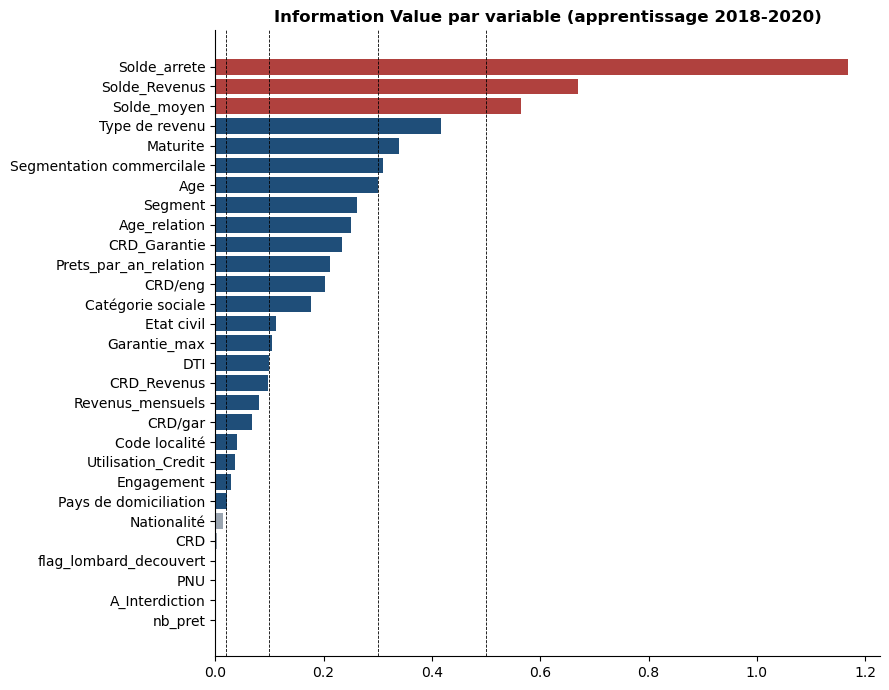

In [4]:
class WoEEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, n_bins=5, min_share=0.05):
        self.n_bins, self.min_share = n_bins, min_share

    def _bins(self, col, s):
        if col in self.edges_:
            out = pd.cut(s, self.edges_[col], include_lowest=True).astype(str)
        else:
            out = s.astype(str).where(s.astype(str).isin(self.keep_[col]), 'Autre')
        return out.where(s.notna(), 'Manquant')

    @staticmethod
    def _monotone(s, y, edges):
        # Fusionne les classes voisines jusqu'a ce que le taux de defaut varie dans un seul sens
        ok = s.notna().to_numpy()
        while len(edges) > 2:
            rate = pd.Series(y[ok]).groupby(pd.cut(s[ok], edges, labels=False, include_lowest=True).to_numpy()).mean()
            rate = rate.reindex(range(len(edges) - 1)).ffill().bfill().to_numpy()
            diffs = np.diff(rate) * np.sign(rate[-1] - rate[0] or 1)
            bad = np.where(diffs < 0)[0]
            if len(bad) == 0:
                break
            edges = np.delete(edges, bad[0] + 1)
        return edges

    def fit(self, X, y):
        y = np.asarray(y)
        self.edges_, self.keep_, self.woe_, self.iv_, self.tables_ = {}, {}, {}, {}, {}
        for col in X.columns:
            s = X[col]
            if pd.api.types.is_numeric_dtype(s):
                q = np.unique(np.nanquantile(s.dropna(), np.linspace(0, 1, self.n_bins + 1)))
                self.edges_[col] = self._monotone(s, y, np.r_[-np.inf, q[1:-1], np.inf] if len(q) > 2 else np.array([-np.inf, np.inf]))
            else:
                share = s.astype(str).value_counts(normalize=True)
                self.keep_[col] = set(share[share >= self.min_share].index)
            b = self._bins(col, s)
            t = pd.crosstab(b, y).reindex(columns=[0, 1], fill_value=0) + 0.5     # lissage pour les classes sans defaut
            good, bad = t[0] / t[0].sum(), t[1] / t[1].sum()
            woe = np.log(good / bad)
            self.woe_[col] = woe.to_dict()
            self.iv_[col] = float(((good - bad) * woe).sum())
            if col in self.edges_:
                order = [str(i) for i in pd.IntervalIndex.from_breaks(self.edges_[col], closed='right')]
                t, woe, good, bad = (z.reindex([o for o in order + ['Manquant'] if o in z.index]) for z in (t, woe, good, bad))
            self.tables_[col] = pd.DataFrame({'effectif': (t[0] + t[1] - 1).astype(int), 'defauts': (t[1] - 0.5).astype(int),
                                              'taux_defaut': (t[1] - 0.5) / (t[0] + t[1] - 1), 'WoE': woe})
        return self

    def transform(self, X):
        return pd.DataFrame({c: self._bins(c, X[c]).map(self.woe_[c]).fillna(0.0).astype(float) for c in X.columns},
                            index=X.index)

woe = WoEEncoder(n_bins=5).fit(X_train, y_train)
iv = pd.Series(woe.iv_).sort_values(ascending=False)
force = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 0.5, 99], labels=['inutile', 'faible', 'moyen', 'fort', 'suspect'])
print(pd.DataFrame({'IV': iv.round(3), 'force': force}).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(iv.index[::-1], iv.values[::-1], color=[RED if v > 0.5 else BLUE if v >= 0.02 else GRAY for v in iv.values[::-1]])
for x_, lab in [(0.02, '0,02'), (0.1, '0,1'), (0.3, '0,3'), (0.5, '0,5')]:
    ax.axvline(x_, color='black', lw=0.6, ls='--')
ax.set_title('Information Value par variable (apprentissage 2018-2020)', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/information_value.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Stabilité dans le temps

Une variable utile aujourd'hui doit le rester demain. On compare sa distribution en 2018-2019 et en 2020 avec l'**indice de stabilité de population (PSI)**. Ce calcul n'utilise que les années d'apprentissage.

En pratique bancaire, un PSI inférieur à 0,1 signale une variable stable, et un PSI supérieur à 0,25 un changement important. Avec si peu de défauts, on retient le seuil strict de 0,1.

In [5]:
def psi(a, b, bins=5):
    if pd.api.types.is_numeric_dtype(a):
        q = np.unique(np.nanquantile(a.dropna(), np.linspace(0, 1, bins + 1)))
        e = np.r_[-np.inf, q[1:-1], np.inf]
        a, b = (pd.cut(x, e).astype(str).where(x.notna(), 'NA') for x in (a, b))
    pa, pb = a.astype(str).value_counts(normalize=True), b.astype(str).value_counts(normalize=True)
    idx = pa.index.union(pb.index)
    pa, pb = pa.reindex(idx, fill_value=0) + 1e-4, pb.reindex(idx, fill_value=0) + 1e-4
    return float(((pa - pb) * np.log(pa / pb)).sum())

stab = pd.Series({c: psi(train.loc[train['annee'] <= 2019, c], train.loc[train['annee'] == 2020, c]) for c in features})
stable = [c for c in features if stab[c] <= 0.1]
print('PSI 2018-2019 contre 2020 (variables au-dessus de 0,05) :')
print(stab[stab > 0.05].sort_values(ascending=False).round(3).to_string())
print('Variables instables ecartees :', [c for c in features if c not in stable])

PSI 2018-2019 contre 2020 (variables au-dessus de 0,05) :
Solde_arrete     1.442
CRD/gar          0.166
CRD_Garantie     0.163
Age_relation     0.063
Garantie_max     0.058
Code localité    0.057
Variables instables ecartees : ['Solde_arrete', 'CRD/gar', 'CRD_Garantie']


## 4. Sélection des variables

1. On garde les variables **stables** dont l'**IV est au moins égale à 0,02**, et on écarte celles au-dessus de **0,5**, suspectes de fuite d'information.
2. **Corrélation** : si deux variables encodées ont une corrélation supérieure à 0,7 en valeur absolue, on garde celle d'IV la plus forte.
3. **Stepwise forward** : on ajoute les variables une à une tant que l'AUC en validation croisée groupée progresse d'au moins 0,002.

In [6]:
kept = [c for c in iv.index if 0.02 <= iv[c] <= 0.5 and c in stable]
W = woe.transform(X_train[kept])
corr = W.corr().abs()
selected = []
for c in kept:                                   # kept est trie par IV decroissante
    if all(corr.loc[c, s] <= 0.7 for s in selected):
        selected.append(c)
print('Apres IV et correlation :', selected)

def cv_auc(cols, C=1.0):
    pipe = Pipeline([('woe', WoEEncoder(n_bins=5)), ('lr', LogisticRegression(C=C, max_iter=2000))])
    p = cross_val_predict(pipe, X_train[cols], y_train, groups=g_train, cv=CV, method='predict_proba')[:, 1]
    return roc_auc_score(y_train, p)

def stepwise(candidates):
    chosen, best_auc, history = [], 0.5, []
    while True:
        scores = {c: cv_auc(chosen + [c]) for c in candidates if c not in chosen}
        if not scores:
            break
        c, a = max(scores.items(), key=lambda kv: kv[1])
        if a - best_auc < 0.002:
            break
        chosen.append(c)
        best_auc = a
        history.append((len(chosen), c, round(a, 4)))
    print(pd.DataFrame(history, columns=['etape', 'variable ajoutee', 'AUC (CV groupee)']).to_string(index=False))
    return chosen

chosen = stepwise(selected)
print('\nVariables du score :', chosen)

Apres IV et correlation : ['Type de revenu', 'Maturite', 'Segmentation commercilale', 'Age', 'Segment', 'Age_relation', 'CRD/eng', 'Catégorie sociale', 'Etat civil', 'Garantie_max', 'DTI', 'Revenus_mensuels', 'Code localité', 'Utilisation_Credit', 'Engagement', 'Pays de domiciliation']


 etape          variable ajoutee  AUC (CV groupee)
     1                  Maturite            0.6137
     2 Segmentation commercilale            0.6673
     3                   CRD/eng            0.7131
     4              Age_relation            0.7337

Variables du score : ['Maturite', 'Segmentation commercilale', 'CRD/eng', 'Age_relation']


## 5. Régression logistique réglée et modèle challenger

Les hyperparamètres sont réglés par validation croisée groupée sur l'apprentissage :
- pour la **régression logistique** : le nombre de classes WoE (3 à 6, avant fusion des classes non monotones) et la force de régularisation `C` ;
- pour le **challenger**, un gradient boosting sur les variables brutes : le taux d'apprentissage, le nombre de feuilles, la taille des feuilles et la régularisation.

Le challenger utilise **les mêmes variables autorisées** que le score, sans les soldes suspects. Il dit si la grille, simple et lisible, perd beaucoup en discrimination. Une seconde version du challenger, qui inclut les soldes, mesure ce que ces variables apportent : avant de les utiliser, il faudrait vérifier avec la banque à quelle date elles sont arrêtées.

In [7]:
score_pipe = Pipeline([('woe', WoEEncoder()), ('lr', LogisticRegression(max_iter=2000))])
gs = GridSearchCV(score_pipe, {'woe__n_bins': [3, 4, 5, 6], 'lr__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                  cv=CV, scoring='roc_auc', n_jobs=-1).fit(X_train[chosen], y_train, groups=g_train)
scorecard = gs.best_estimator_
print('Regression logistique :', gs.best_params_, f'| AUC CV = {gs.best_score_:.4f}')

def make_challenger(cols):
    cat = [c for c in cols if not pd.api.types.is_numeric_dtype(X_train[c])]
    num = [c for c in cols if c not in cat]
    pipe = Pipeline([
        ('prep', ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                                                           encoded_missing_value=-2), cat)], remainder='passthrough')),
        ('gb', HistGradientBoostingClassifier(random_state=SEED, categorical_features=list(range(len(cat))), max_iter=300))])
    space = {'gb__learning_rate': loguniform(0.01, 0.2), 'gb__max_leaf_nodes': randint(3, 31),
             'gb__min_samples_leaf': randint(20, 200), 'gb__l2_regularization': loguniform(1e-3, 10)}
    return RandomizedSearchCV(pipe, space, n_iter=40, cv=CV, scoring='roc_auc', random_state=SEED,
                              n_jobs=-1).fit(X_train[cat + num], y_train, groups=g_train), cat + num

eligible = [c for c in features if iv[c] <= 0.5 and c in stable]   # memes exclusions que le score
suspect = [c for c in features if iv[c] > 0.5]
rs, chal_cols = make_challenger(eligible)
rs_all, chal_cols_all = make_challenger(features)
print('Challenger, memes variables que le score :', f'AUC CV = {rs.best_score_:.4f}')
print('Challenger, avec les soldes suspects', suspect, f': AUC CV = {rs_all.best_score_:.4f}')

Regression logistique : {'lr__C': 10, 'woe__n_bins': 3} | AUC CV = 0.7567


Challenger, memes variables que le score : AUC CV = 0.7406
Challenger, avec les soldes suspects ['Solde_moyen', 'Solde_arrete', 'Solde_Revenus'] : AUC CV = 0.8088


## 6. Performance hors période (2021)

On mesure :
- la **discrimination** : AUC, Gini = 2 × AUC − 1, et KS ;
- la **calibration** : la PD moyenne prédite comparée au taux de défaut observé en 2021, et le score de Brier.

Avec seulement 49 défauts en 2021, un intervalle de confiance par bootstrap (1 000 tirages) accompagne l'AUC.

                                       AUC          IC 95 %    Gini      KS  PD moyenne  Taux observe   Brier
                                                                                                             
Score - apprentissage (CV groupee)  0.7519  [0.689 ; 0.811]  0.5038  0.4327      0.0189        0.0190  0.0185
Score - test 2021                   0.5839  [0.500 ; 0.662]  0.1679  0.1709      0.0364        0.0223  0.0228
Challenger - test 2021              0.8039  [0.724 ; 0.872]  0.6077  0.5069      0.0137        0.0223  0.0184
Challenger avec soldes - test 2021  0.8851  [0.834 ; 0.932]  0.7702  0.6350      0.0136        0.0223  0.0180


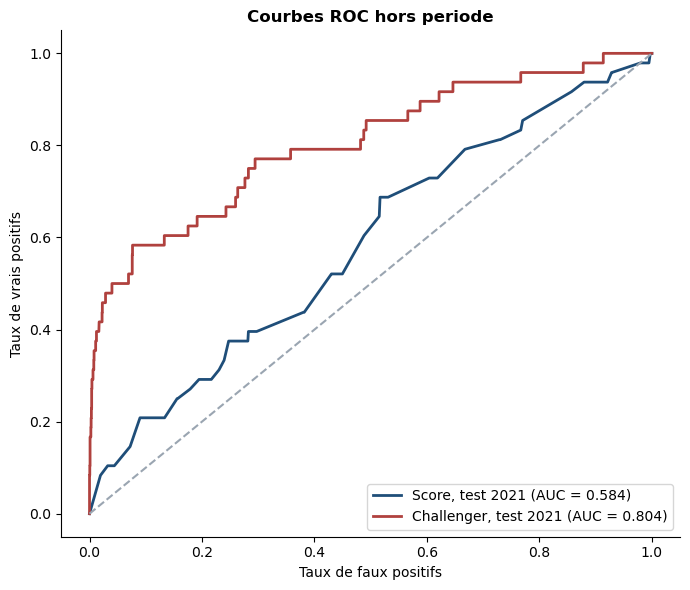

In [8]:
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def auc_ci(y, p, B=1000):
    rng = np.random.RandomState(SEED)
    y, p, vals = np.asarray(y), np.asarray(p), []
    for _ in range(B):
        i = rng.randint(0, len(y), len(y))
        if y[i].min() != y[i].max():
            vals.append(roc_auc_score(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

pd_train = cross_val_predict(scorecard, X_train[chosen], y_train, groups=g_train, cv=CV, method='predict_proba')[:, 1]
pd_test = scorecard.predict_proba(X_test[chosen])[:, 1]
pd_chal = rs.best_estimator_.predict_proba(X_test[chal_cols])[:, 1]
pd_chal_all = rs_all.best_estimator_.predict_proba(X_test[chal_cols_all])[:, 1]

rows = []
for name, y_, p_ in [('Score - apprentissage (CV groupee)', y_train, pd_train), ('Score - test 2021', y_test, pd_test),
                     ('Challenger - test 2021', y_test, pd_chal), ('Challenger avec soldes - test 2021', y_test, pd_chal_all)]:
    a = roc_auc_score(y_, p_)
    lo, hi = auc_ci(y_, p_)
    rows.append({'': name, 'AUC': a, 'IC 95 %': f'[{lo:.3f} ; {hi:.3f}]', 'Gini': 2 * a - 1, 'KS': ks(y_, p_),
                 'PD moyenne': p_.mean(), 'Taux observe': np.mean(y_), 'Brier': brier_score_loss(y_, p_)})
perf = pd.DataFrame(rows).set_index('')
print(perf.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
for name, y_, p_, col in [('Score, test 2021', y_test, pd_test, BLUE), ('Challenger, test 2021', y_test, pd_chal, RED)]:
    f, t, _ = roc_curve(y_, p_)
    ax.plot(f, t, color=col, lw=2, label=f'{name} (AUC = {roc_auc_score(y_, p_):.3f})')
ax.plot([0, 1], [0, 1], color=GRAY, ls='--')
ax.set_xlabel('Taux de faux positifs')
ax.set_ylabel('Taux de vrais positifs')
ax.set_title('Courbes ROC hors periode', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/roc_hors_periode.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Variante COVID : meme methode, apprentissage sur 2018-2019 seulement
no20 = train['annee'] <= 2019
sc_no20 = clone(scorecard).fit(X_train.loc[no20, chosen], y_train[no20])
p_no20 = sc_no20.predict_proba(X_test[chosen])[:, 1]
print(f"Score appris sur 2018-2020 : AUC 2021 = {roc_auc_score(y_test, pd_test):.3f}")
print(f"Score appris sur 2018-2019 (sans l annee COVID) : AUC 2021 = {roc_auc_score(y_test, p_no20):.3f}")

# Diagnostic de derive (sert a expliquer le resultat, pas a choisir le modele)
drift = pd.Series({c: psi(X_train[c], X_test[c]) for c in features}).sort_values(ascending=False)
print('\nPSI apprentissage contre 2021 (au-dessus de 0,25) :')
print(drift[drift > 0.25].round(3).to_string())

Score appris sur 2018-2020 : AUC 2021 = 0.584
Score appris sur 2018-2019 (sans l annee COVID) : AUC 2021 = 0.602



PSI apprentissage contre 2021 (au-dessus de 0,25) :
CRD/eng         1.724
Solde_arrete    0.590
CRD_Garantie    0.504
Garantie_max    0.300


**Lecture.**
- **En validation croisée sur 2018-2020, la grille obtient une AUC de 0,75** (Gini de 0,50), avec des PD bien calibrées : 1,89 % prédit pour 1,90 % observé.
- **Sur 2021, elle chute à 0,58.** Le diagnostic de dérive explique pourquoi : `CRD/eng`, la variable la plus lourde de la grille, change complètement de distribution en 2021 (PSI de 1,72, alors que 0,25 signale déjà un changement majeur). C'est sans doute un changement de calcul ou de source des données, invisible dans les années d'apprentissage.
- **Retirer l'année COVID améliore à peine le résultat** (0,60). Les reports d'échéances de 2020 ne sont donc pas la cause principale.
- **Le challenger (gradient boosting) atteint 0,80 en 2021 avec les mêmes variables autorisées.** Il tolère mieux la variable en rupture. Avec les soldes suspects, il monte à 0,89 : ces variables portent beaucoup d'information, mais il faudrait vérifier leur date d'arrêté avant de les utiliser.

### Décision de validation : retirer la variable en rupture

Le contrôle de 2021 montre que `CRD/eng` change brutalement de distribution (PSI supérieur à 1). C'est probablement un changement de calcul ou de source dans le système d'information. Une banque ne garderait pas une variable dans cet état : on la retire, puis on refait la sélection et le réglage, toujours sur 2018-2020 seulement.

Cette décision utilise une information de 2021. Le test qui suit n'est donc plus totalement indépendant, et son AUC est à lire comme une estimation un peu optimiste. La grille de points et l'échelle de notation présentées ensuite portent sur ce modèle révisé.

In [10]:
broken = [c for c in features if drift[c] > 0.25]
print('Variables ecartees pour rupture en 2021 :', broken)
chosen = stepwise([c for c in selected if c not in broken])
gs = GridSearchCV(score_pipe, {'woe__n_bins': [3, 4, 5, 6], 'lr__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                  cv=CV, scoring='roc_auc', n_jobs=-1).fit(X_train[chosen], y_train, groups=g_train)
scorecard = gs.best_estimator_
pd_train = cross_val_predict(scorecard, X_train[chosen], y_train, groups=g_train, cv=CV, method='predict_proba')[:, 1]
pd_test = scorecard.predict_proba(X_test[chosen])[:, 1]
lo, hi = auc_ci(y_test, pd_test)
print('Parametres :', gs.best_params_)
print(f"Score revise : AUC CV = {roc_auc_score(y_train, pd_train):.3f} | AUC 2021 = {roc_auc_score(y_test, pd_test):.3f} "
      f"[{lo:.3f} ; {hi:.3f}] | Gini 2021 = {2 * roc_auc_score(y_test, pd_test) - 1:.3f} | KS 2021 = {ks(y_test, pd_test):.3f}")
print(f"PD moyenne 2021 = {pd_test.mean():.4f} | taux observe = {y_test.mean():.4f}")

Variables ecartees pour rupture en 2021 : ['Garantie_max', 'Solde_arrete', 'CRD/eng', 'CRD_Garantie']


 etape          variable ajoutee  AUC (CV groupee)
     1                  Maturite            0.6137
     2 Segmentation commercilale            0.6673
     3              Age_relation            0.6876


Parametres : {'lr__C': 3, 'woe__n_bins': 3}
Score revise : AUC CV = 0.701 | AUC 2021 = 0.640 [0.552 ; 0.716] | Gini 2021 = 0.279 | KS 2021 = 0.245
PD moyenne 2021 = 0.0203 | taux observe = 0.0223


**Lecture.** Sans les variables en rupture, la grille ne garde que **trois variables stables** : la maturité, la segmentation commerciale et l'ancienneté de la relation. Son AUC en 2021 remonte à **0,64**, et surtout ses PD restent **bien calibrées** : 2,03 % prédit pour 2,23 % observé. Le niveau global du risque est donc correctement estimé, même si le classement des clients reste modeste.

## 7. Grille de score

Les coefficients sont traduits en **points**, selon la convention usuelle :
- un score de **600 points** correspond à une cote de 50 bons clients pour 1 défaut ;
- **20 points** de plus doublent cette cote.

Chaque client additionne les points de ses classes : plus le score est élevé, plus le client est sûr.

In [11]:
enc, lr = scorecard.named_steps['woe'], scorecard.named_steps['lr']
factor = 20 / np.log(2)
offset = 600 - factor * np.log(50)
n = len(chosen)
grid = []
for c, beta in zip(chosen, lr.coef_[0]):
    t = enc.tables_[c].copy()
    t['points'] = (offset / n - factor * (beta * t['WoE'] + lr.intercept_[0] / n)).round(0).astype(int)
    t.insert(0, 'variable', c)
    grid.append(t.reset_index(names='classe'))
grid = pd.concat(grid, ignore_index=True)
print(grid[['variable', 'classe', 'effectif', 'taux_defaut', 'WoE', 'points']].round(3).to_string(index=False))
print('\nCoefficients (sur WoE, negatifs attendus) :', dict(zip(chosen, lr.coef_[0].round(3))))

                 variable                             classe  effectif  taux_defaut    WoE  points
                 Maturite                        (-inf, 9.0]      1276        0.034 -0.606     187
                 Maturite                         (9.0, inf]      2295        0.010  0.602     214
Segmentation commercilale                              Autre       491        0.047 -0.914     178
Segmentation commercilale                   Indéterminé (S0)       801        0.014  0.324     208
Segmentation commercilale                           Manquant      1141        0.016  0.200     205
Segmentation commercilale Revenus salariés - AB (24-40) (S4)       842        0.010  0.680     217
Segmentation commercilale Revenus salariés - AB (41-60) (S5)       296        0.027 -0.382     191
             Age_relation                       (-inf, 17.0]      1234        0.011  0.512     210
             Age_relation                       (17.0, 36.0]      1183        0.014  0.279     205
          

## 8. Échelle de notation

Les classes de risque sont construites sur l'**apprentissage**, à partir des PD hors échantillon de la validation croisée :
- on part de 7 classes de même effectif, et on en retire tant que le taux de défaut observé n'est pas strictement croissant d'une classe à l'autre (jusqu'à 2 classes au minimum) ;
- chaque classe doit compter au moins 5 défauts.

Les bornes obtenues sont ensuite appliquées telles quelles aux clients de 2021. Le test ne sert qu'à vérifier l'échelle, pas à la choisir.

2 classes retenues sur l apprentissage
        effectif  defauts  pd_moyenne  taux_observe
classe                                             
C1          1788       13      0.0073        0.0073
C2          1783       55      0.0303        0.0308

Meme echelle appliquee a 2021 :
        effectif  defauts  pd_moyenne  taux_observe  part_%
classe                                                     
C1           863       12      0.0072        0.0139  40.065
C2          1291       36      0.0290        0.0279  59.935


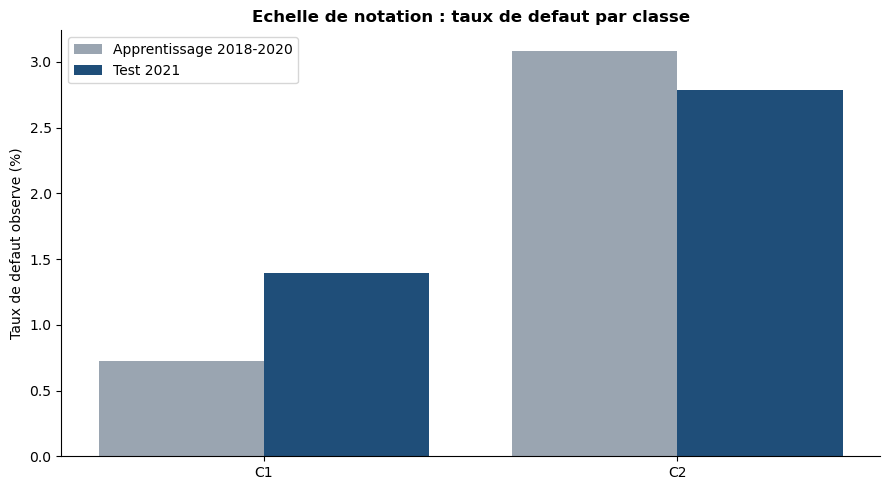

In [12]:
def scale_table(p, y, edges):
    cls = pd.cut(p, edges, labels=[f'C{i}' for i in range(1, len(edges))], include_lowest=True)
    return pd.DataFrame({'classe': cls, 'pd': p, 'defaut': np.asarray(y)}).groupby('classe', observed=False).agg(
        effectif=('defaut', 'size'), defauts=('defaut', 'sum'), pd_moyenne=('pd', 'mean'), taux_observe=('defaut', 'mean'))

for k in range(7, 1, -1):
    _, edges = pd.qcut(pd_train, k, retbins=True, duplicates='drop')
    edges[0], edges[-1] = 0, 1
    t = scale_table(pd_train, y_train, edges)
    if t['taux_observe'].is_monotonic_increasing and t['taux_observe'].is_unique and t['defauts'].min() >= 5:
        break
print(f'{len(edges) - 1} classes retenues sur l apprentissage')
print(t.round(4).to_string())
t_test = scale_table(pd_test, y_test, edges)
t_test['part_%'] = 100 * t_test['effectif'] / t_test['effectif'].sum()
print('\nMeme echelle appliquee a 2021 :')
print(t_test.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(t_test))
ax.bar(x - 0.2, 100 * t['taux_observe'], 0.4, color=GRAY, label='Apprentissage 2018-2020')
ax.bar(x + 0.2, 100 * t_test['taux_observe'], 0.4, color=BLUE, label='Test 2021')
ax.set_xticks(x)
ax.set_xticklabels(t_test.index.astype(str))
ax.set_ylabel('Taux de defaut observe (%)')
ax.set_title('Echelle de notation : taux de defaut par classe', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('figures/echelle_notation.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.** Avec seulement 68 défauts dans l'apprentissage, l'échelle n'est strictement croissante qu'avec **deux classes**. La classe C1 a 0,7 % de défauts, la classe C2 environ 3 %. Appliquée à 2021, elle garde le bon ordre : 1,4 % contre 2,8 %. Une échelle plus fine demanderait davantage d'historique de défauts.

## 9. Conclusion

| Modèle | AUC CV 2018-2020 | AUC 2021 | PD prédite / observée en 2021 |
|---|---|---|---|
| Grille de score initiale | 0,75 | 0,58 | 3,6 % / 2,2 % |
| **Grille révisée (variables stables)** | 0,70 | **0,64** | **2,0 % / 2,2 %** |
| Challenger gradient boosting | 0,74 | 0,80 | 1,4 % / 2,2 % |

**À retenir**
- **Une bonne validation croisée ne suffit pas.** C'est le test hors période qui a révélé la rupture de `CRD/eng` en 2021. Le suivi de stabilité (PSI) doit faire partie du dispositif de notation.
- **La grille révisée est simple, lisible et calibrée,** mais elle discrimine peu : elle ne garde que trois variables stables, faute de défauts en nombre suffisant.
- **Le gradient boosting discrimine nettement mieux.** En banque, il servirait de modèle challenger pour surveiller la grille, en attendant plus d'historique et des variables fiabilisées.
- **Ce qui a changé par rapport à la première version :**
  - plus de rééquilibrage SMOTE, donc des PD calibrées ;
  - une validation hors période et groupée par client ;
  - une échelle de notation choisie sur l'apprentissage, et non plus sur le test ;
  - une grille de points.

  L'AUC de 0,82 annoncée auparavant venait d'un test aléatoire contenant les mêmes clients que l'apprentissage.